# 02 · Preprocesamiento
Partición estratificada 70/15/15 (se guarda en `data/processed/`) y verificación del pipeline `tf.data`.

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from src.train import load_config
cfg = load_config("configs/baseline.yaml")
RAW = cfg["data"]["raw_dir"]

I0000 00:00:1792859257.697164   17770 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
from src.data import make_splits

splits = make_splits(RAW, cfg["data"]["split"], cfg["data"]["seed"])
print(splits.split.value_counts())
splits.groupby(["split", "label"]).size().unstack(0).head()

split
train    60900
val      13050
test     13050
Name: count, dtype: int64


split,test,train,val
label,,,
A,450,2100,450
B,450,2100,450
C,450,2100,450
D,450,2100,450
E,450,2100,450


I0000 00:00:1792859263.710439   17770 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5560 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060, pci bus id: 0000:10:00.0, compute capability: 8.9


Batch: (64, 128, 128, 3) <dtype: 'float32'> | etiquetas: (64,)


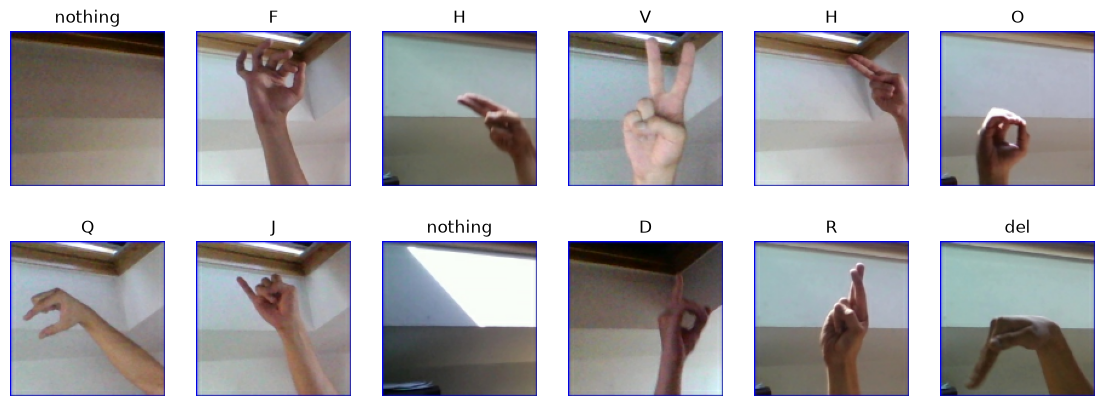

In [3]:
from src.data import build_datasets
import matplotlib.pyplot as plt

datasets, class_names, _ = build_datasets(cfg)
x, y = next(iter(datasets["train"]))
print("Batch:", x.shape, x.dtype, "| etiquetas:", y.shape)

fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for ax, img, lab in zip(axes.flat, x, y):
    ax.imshow(img.numpy().astype("uint8"))
    ax.set_title(class_names[lab])
    ax.axis("off")
plt.show()